In [46]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [47]:
def sigmoid(x):
    return 1/(1+np.exp(-x))

# Derivative of sigmoid function
def sigmoid_derivative(activated_x):
    return activated_x * (1 - activated_x)

def MeanSquareErrorLoss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

In [48]:
df = pd.read_csv("Xor_Dataset.csv")
df.head()

,X,Y,Z
0,0,0,0
1,0,1,1
2,1,1,0
3,1,1,0
4,0,0,0


In [49]:
X = df[["X", "Y"]].values
y = df[["Z"]].values

X, y

(array([[0, 0],
        [0, 1],
        [1, 1],
        ...,
        [1, 1],
        [1, 1],
        [1, 1]], shape=(10000, 2)),
 array([[0],
        [1],
        [0],
        ...,
        [0],
        [0],
        [0]], shape=(10000, 1)))

In [50]:
input_nodes = 2
hidden_nodes = 2
output_nodes = 1

W1 = np.random.uniform(-1, 1, (input_nodes, hidden_nodes))
b1 = np.random.uniform(-1, 1, (1, hidden_nodes))

W2 = np.random.uniform(-1, 1, (hidden_nodes, output_nodes))
b2 = np.random.uniform(-1, 1, (1, output_nodes))

In [51]:
EPOCHS = 10000
LEARNING_RATE = 0.5
losses = []
for epoch in range(EPOCHS):

    # Forward Propogation
    Z1 = np.dot(X, W1) + b1
    A1 = sigmoid(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    current_loss = MeanSquareErrorLoss(y, A2)
    losses.append(current_loss)

    m = X.shape[0]

    # Backward Propogation
    dL_dA2 = (A2 - y) / m
    dZ2 = dL_dA2 * sigmoid_derivative(A2)

    dW2 = np.dot(A1.T, dZ2)
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dL_dA1 = np.dot(dZ2, W2.T)
    dZ1 = dL_dA1 * sigmoid_derivative(A1)
    dW1 = np.dot(X.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    W1 -= LEARNING_RATE * dW1
    b1 -= LEARNING_RATE * db1
    W2 -= LEARNING_RATE * dW2
    b2 -= LEARNING_RATE * db2
    
    if epoch == 0 or (epoch + 1) % 1000 == 0:
        print(f"Epoch {epoch + 1:<5} | MSE Loss: {current_loss:.6f}")

Epoch 1     | MSE Loss: 0.298145
Epoch 1000  | MSE Loss: 0.249952
Epoch 2000  | MSE Loss: 0.249864
Epoch 3000  | MSE Loss: 0.249423
Epoch 4000  | MSE Loss: 0.244843
Epoch 5000  | MSE Loss: 0.208283
Epoch 6000  | MSE Loss: 0.128956
Epoch 7000  | MSE Loss: 0.024483
Epoch 8000  | MSE Loss: 0.009600
Epoch 9000  | MSE Loss: 0.005622
Epoch 10000 | MSE Loss: 0.003895


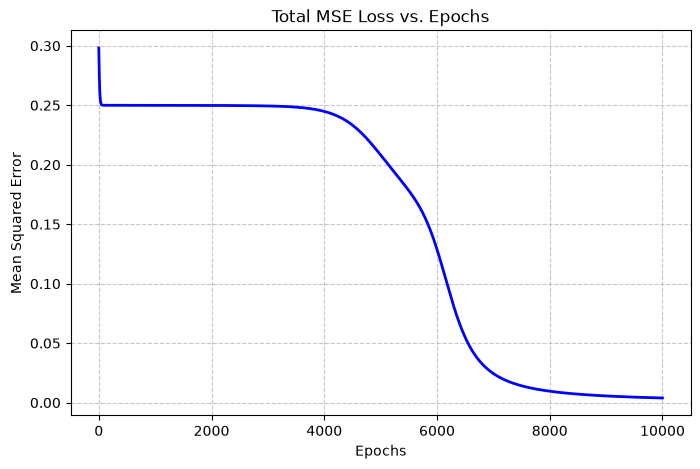

FINAL INFERENCE VALIDATION
Inputs (X,Y): [0, 0] | Target (Z): 0 | Predicted Prob: 0.0653 --> Output: 0
Inputs (X,Y): [0, 1] | Target (Z): 1 | Predicted Prob: 0.9402 --> Output: 1
Inputs (X,Y): [1, 1] | Target (Z): 0 | Predicted Prob: 0.0648 --> Output: 0
Inputs (X,Y): [1, 1] | Target (Z): 0 | Predicted Prob: 0.0648 --> Output: 0
Inputs (X,Y): [0, 0] | Target (Z): 0 | Predicted Prob: 0.0653 --> Output: 0
Inputs (X,Y): [1, 0] | Target (Z): 1 | Predicted Prob: 0.9405 --> Output: 1
Inputs (X,Y): [1, 1] | Target (Z): 0 | Predicted Prob: 0.0648 --> Output: 0
Inputs (X,Y): [1, 1] | Target (Z): 0 | Predicted Prob: 0.0648 --> Output: 0
Inputs (X,Y): [0, 1] | Target (Z): 1 | Predicted Prob: 0.9402 --> Output: 1
Inputs (X,Y): [1, 0] | Target (Z): 1 | Predicted Prob: 0.9405 --> Output: 1
Inputs (X,Y): [0, 0] | Target (Z): 0 | Predicted Prob: 0.0653 --> Output: 0
Inputs (X,Y): [1, 1] | Target (Z): 0 | Predicted Prob: 0.0648 --> Output: 0
Inputs (X,Y): [1, 0] | Target (Z): 1 | Predicted Prob: 0.9405

In [52]:
plt.figure(figsize=(8, 5))
plt.plot(range(EPOCHS), losses, color='blue', linewidth=2)
plt.title('Total MSE Loss vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print("FINAL INFERENCE VALIDATION")

final_Z1 = np.dot(X, W1) + b1
final_A1 = sigmoid(final_Z1)
final_Z2 = np.dot(final_A1, W2) + b2
final_predictions = sigmoid(final_Z2)

for i in range(len(X)):
    input_val = X[i].tolist()
    target_val = int(y[i][0])
    pred_val = final_predictions[i][0]
    rounded_pred = 1 if pred_val >= 0.5 else 0
    print(f"Inputs (X,Y): {input_val} | Target (Z): {target_val} | Predicted Prob: {pred_val:.4f} --> Output: {rounded_pred}")

In [53]:
from sklearn.metrics import accuracy_score
rounded_predictions = (final_predictions >= 0.5).astype(int)
accuracy = accuracy_score(y, rounded_predictions)
print(f"\nOverall Accuracy: {accuracy * 100:.2f}%")


Overall Accuracy: 100.00%
